# Bài tập 6: Chọn các biến quan trọng ảnh hưởng đến giá xe

## 1. Đọc dữ liệu

In [13]:
import pandas as pd
import seaborn as sns
import numpy as np
from scipy import stats

In [28]:
df = pd.read_csv('../dataset/EDA_automobile.csv')
df

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,9.5,114.0,5400.0,23,28,16845,10.217391,Medium,0,1
197,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,8.7,160.0,5300.0,19,25,19045,12.368421,High,0,1
198,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,8.8,134.0,5500.0,18,23,21485,13.055556,Medium,0,1
199,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,23.0,106.0,4800.0,26,27,22470,9.038462,Medium,1,0


In [29]:
df.replace(to_replace="?", value=np.nan, inplace=True)

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,9.5,114.0,5400.0,23,28,16845,10.217391,Medium,0,1
197,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,8.7,160.0,5300.0,19,25,19045,12.368421,High,0,1
198,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,8.8,134.0,5500.0,18,23,21485,13.055556,Medium,0,1
199,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,23.0,106.0,4800.0,26,27,22470,9.038462,Medium,1,0


In [30]:
df.dropna(inplace=True)


In [33]:
df

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,9.5,114.0,5400.0,23,28,16845.0,10.217391,Medium,0,1
197,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,8.7,160.0,5300.0,19,25,19045.0,12.368421,High,0,1
198,-1,95,volvo,std,four,sedan,rwd,front,109.1,0.907256,...,8.8,134.0,5500.0,18,23,21485.0,13.055556,Medium,0,1
199,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,0.907256,...,23.0,106.0,4800.0,26,27,22470.0,9.038462,Medium,1,0


In [31]:
df['price']=df['price'].astype(float)

## 2. Vét cạn từng biến

### 2.1. engine-size

<Axes: xlabel='engine-size', ylabel='price'>

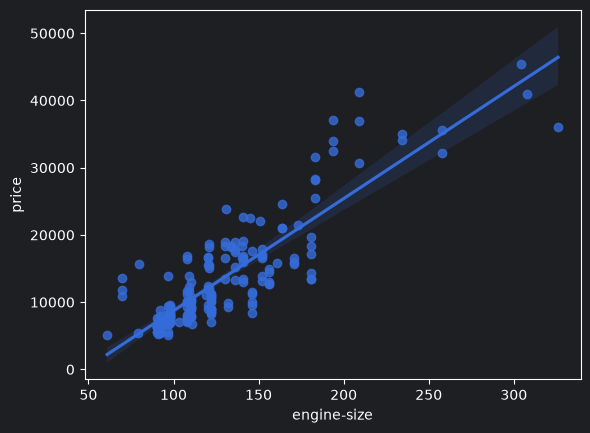

In [34]:
sns.regplot(data=df, x='engine-size', y='price')

In [35]:
df['engine-size'].corr(df['price'])

np.float64(0.8723351674455189)

### 2.2. highway-mpg

<Axes: xlabel='highway-mpg', ylabel='price'>

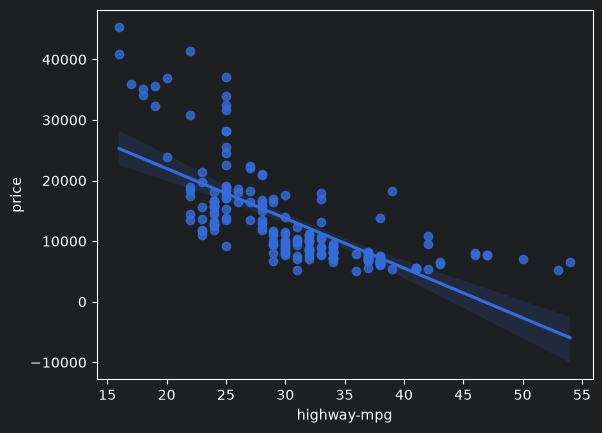

In [36]:
sns.regplot(data=df, x='highway-mpg', y='price')

In [37]:
df['highway-mpg'].corr(df['price'])

np.float64(-0.7046922650589534)

### 2.3. peak-rpm

In [38]:
df['peak-rpm'].corr(df['price'])

np.float64(-0.1016158740746682)

### 2.4. drive-wheels

<Axes: xlabel='drive-wheels', ylabel='price'>

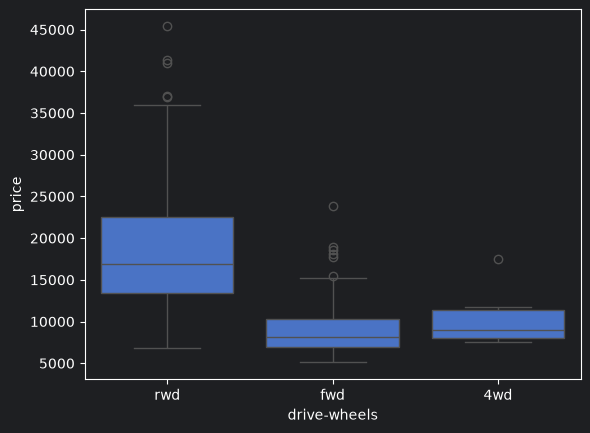

In [39]:
sns.boxplot(data=df, x='drive-wheels', y='price')

In [40]:
nhom = df[['drive-wheels', 'price']].groupby('drive-wheels')
nhom.mean()

,price
drive-wheels,
4wd,10241.000000
fwd,9244.779661
rwd,19757.613333


In [25]:
stats.f_oneway(nhom.get_group('rwd')['price'],
               nhom.get_group('fwd')['price'],
               nhom.get_group('4wd')['price'])

F_onewayResult(statistic=np.float64(66.99073391404411), pvalue=np.float64(9.973317664143584e-22))

### 2.5. symboling

In [42]:
df['symboling'].corr(df['price'])

np.float64(-0.08239118716962354)

In [43]:
nhom_sym = df[['symboling', 'price']].groupby('symboling')
stats.f_oneway(*[gia['price'] for ten, gia in nhom_sym])

F_onewayResult(statistic=np.float64(6.847986667874622), pvalue=np.float64(6.556745663768506e-06))

## 3. Hàm tự động

In [44]:
def kiem_tra_corr(s1, s2) -> bool:
    r = s1.corr(s2)
    return r < -0.3 or r > 0.3

In [45]:
def kiem_tra_anova(s_phan_loai, s_gia) -> bool:
    nhom = s_gia.groupby(s_phan_loai)
    ds_nhom = [gia for ten, gia in nhom]
    f, p = stats.f_oneway(*ds_nhom)
    return p < 0.05

In [46]:
def chon_bien(df) -> list:
    ket_qua = []
    for cot in df.columns:
        if cot == 'price':
            continue
        if pd.api.types.is_numeric_dtype(df[cot]):
            if kiem_tra_corr(df[cot], df['price']):
                ket_qua.append(cot)
            elif df[cot].nunique() <= 10 and kiem_tra_anova(df[cot], df['price']):
                ket_qua.append(cot)
        else:
            if kiem_tra_anova(df[cot], df['price']):
                ket_qua.append(cot)
    return ket_qua

In [47]:
bien_quan_trong = chon_bien(df)
bien_quan_trong

['symboling',
 'make',
 'aspiration',
 'body-style',
 'drive-wheels',
 'engine-location',
 'wheel-base',
 'length',
 'width',
 'curb-weight',
 'engine-type',
 'num-of-cylinders',
 'engine-size',
 'fuel-system',
 'bore',
 'horsepower',
 'city-mpg',
 'highway-mpg',
 'city-L/100km',
 'horsepower-binned']

In [48]:
len(bien_quan_trong)

20

In [49]:
[cot for cot in df.columns if cot not in bien_quan_trong and cot != 'price']

['normalized-losses',
 'num-of-doors',
 'height',
 'stroke',
 'compression-ratio',
 'peak-rpm',
 'diesel',
 'gas']